<a href="https://colab.research.google.com/github/vasquezEmanuel/statoil-iceberg-classifier-challenge/blob/main/04_transfer_learning_y_comparacion_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer learning con distintos backbones y comparación final

Se comparan tres redes preentrenadas en ImageNet (**MobileNetV2**, **ResNet50** y **VGG16**) frente a una CNN pequeña entrenada desde cero, sobre imágenes SAR de Statoil/C-CORE (barco vs. iceberg).

Todos los modelos usan **la misma partición agrupada por ángulo**, sin usar `inc_angle` como entrada, y el mismo aumento de datos (giros y rotaciones de 90°). El entrenamiento de cada backbone tiene dos fases:

1. **Cabeza**: el backbone permanece congelado y solo se entrena el clasificador (tasa de aprendizaje 1e-3).
2. **Ajuste fino parcial**: se descongelan las últimas capas con tasa de aprendizaje 1e-5. El backbone se invoca con `training=False`, de modo que las capas *BatchNorm* conservan sus estadísticas de ImageNet.

Si el ajuste fino no mejora la pérdida de validación de la fase 1, se conservan los pesos de la fase 1. **Se recomienda usar una GPU** (*Entorno de ejecución → Cambiar tipo de entorno*).

## Obtención de los datos

Los datos pertenecen a la competición [Statoil/C-CORE Iceberg Classifier Challenge](https://www.kaggle.com/c/statoil-iceberg-classifier-challenge) y se descargan con la API de Kaggle. Hace falta:

1. Una cuenta de Kaggle y haber aceptado las reglas de la competición (pestaña *Rules* → *I Understand and Accept*). Sin este paso la descarga responde `403 Forbidden`.
2. Un archivo `kaggle.json` con credenciales *legacy*: en Kaggle, *Settings → API → Legacy API Credentials → Create Legacy API Key*.

Al ejecutar la celda se pide subir `kaggle.json`. El archivo se lee, se borra del disco de la sesión y nunca se guarda en el notebook. Solo se descarga `train.json` (1 604 imágenes), el único conjunto con etiquetas.

In [2]:
import os, sys, json, glob, shutil, zipfile, subprocess, importlib.util

COMPETICION = "statoil-iceberg-classifier-challenge"
DATA_DIR = "data"
TRAIN_JSON = os.path.join(DATA_DIR, "train.json")


def _instalar_dependencias():
    faltan = [p for p in ("kaggle", "py7zr") if importlib.util.find_spec(p) is None]
    if faltan:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)


def _cargar_credenciales():
    """Define KAGGLE_USERNAME y KAGGLE_KEY a partir de un kaggle.json (credenciales legacy)."""
    if os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
        return
    ruta = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(ruta):
        with open(ruta) as f:
            cred = json.load(f)
    else:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError(
                "No se encontraron credenciales: coloca kaggle.json en ~/.kaggle/ "
                "o define las variables KAGGLE_USERNAME y KAGGLE_KEY."
            )
        print("Selecciona tu archivo kaggle.json")
        subido = files.upload()
        nombre = next((n for n in subido if n.lower().endswith(".json")), None)
        if nombre is None:
            raise RuntimeError("No se subió ningún archivo .json")
        cred = json.loads(subido[nombre])
        try:
            os.remove(nombre)
        except OSError:
            pass
    if "username" not in cred or "key" not in cred:
        raise RuntimeError(
            "El archivo no contiene 'username' y 'key'. Genera una Legacy API Key en "
            "Kaggle (Settings → API → Legacy API Credentials → Create Legacy API Key)."
        )
    os.environ["KAGGLE_USERNAME"] = cred["username"]
    os.environ["KAGGLE_KEY"] = cred["key"]


def _extraer():
    """Descomprime los .zip / .7z de train que haya en data/ y deja train.json en data/train.json."""
    import py7zr
    hay_trabajo = True
    while hay_trabajo:
        hay_trabajo = False
        for ruta in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True):
            if not os.path.isfile(ruta):
                continue
            nombre, destino = os.path.basename(ruta).lower(), os.path.dirname(ruta)
            if nombre.endswith(".zip") and zipfile.is_zipfile(ruta):
                with zipfile.ZipFile(ruta) as z:
                    for miembro in z.namelist():
                        if "train" in os.path.basename(miembro).lower():
                            z.extract(miembro, destino)
                os.remove(ruta)
                hay_trabajo = True
                break
            if nombre.endswith(".7z") and nombre.startswith("train"):
                with py7zr.SevenZipFile(ruta) as z:
                    z.extractall(path=destino)
                os.remove(ruta)
                hay_trabajo = True
                break
    encontrados = glob.glob(os.path.join(DATA_DIR, "**", "train.json"), recursive=True)
    if encontrados and os.path.abspath(encontrados[0]) != os.path.abspath(TRAIN_JSON):
        carpeta = os.path.relpath(encontrados[0], DATA_DIR).split(os.sep)[0]
        shutil.move(encontrados[0], TRAIN_JSON)
        shutil.rmtree(os.path.join(DATA_DIR, carpeta), ignore_errors=True)


def _descargar():
    os.makedirs(DATA_DIR, exist_ok=True)
    salida = ""
    for extra in (["-f", "train.json.7z"], []):  # primero solo train; si falla, el paquete completo
        cmd = [sys.executable, "-m", "kaggle", "competitions", "download",
               "-c", COMPETICION, "-p", DATA_DIR, *extra]
        r = subprocess.run(cmd, capture_output=True, text=True)
        salida = (r.stdout + "\n" + r.stderr).strip()
        _extraer()
        if os.path.exists(TRAIN_JSON):
            return
    raise RuntimeError(
        "No se pudo obtener train.json. Respuesta de Kaggle:\n\n" + salida + "\n\n"
        "Revisa lo siguiente:\n"
        "  1. Aceptaste las reglas en https://www.kaggle.com/c/" + COMPETICION + "/rules (error 403).\n"
        "  2. El kaggle.json es una Legacy API Key vigente; crear una nueva invalida la anterior (error 401).\n"
        "  3. Alternativa manual: descarga train.json.7z desde la pestaña Data de la competición, "
        "súbelo a la carpeta data/ y vuelve a ejecutar esta celda."
    )


if not os.path.exists(TRAIN_JSON):
    _instalar_dependencias()
    _extraer()  # cubre el caso de que el archivo ya esté en data/
if not os.path.exists(TRAIN_JSON):
    _cargar_credenciales()
    _descargar()

print(f"Datos listos: {TRAIN_JSON} ({os.path.getsize(TRAIN_JSON) / 1e6:.0f} MB)")

Datos listos: data/train.json (196 MB)


## Funciones

In [3]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import log_loss, accuracy_score, roc_auc_score, roc_curve, confusion_matrix

warnings.filterwarnings("ignore")
SEMILLA = 42
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def cargar_datos(ruta=TRAIN_JSON):
    df = pd.read_json(ruta)
    df["inc_angle"] = pd.to_numeric(df["inc_angle"], errors="coerce")  # 'na' -> NaN
    return df


def construir_imagenes(df):
    """Tensor N x 75 x 75 x 3 con las bandas HH, HV y su promedio."""
    b1 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_1"]])
    b2 = np.stack([np.asarray(v, dtype=np.float32).reshape(75, 75) for v in df["band_2"]])
    return np.stack([b1, b2, (b1 + b2) / 2], axis=-1)


def grupos_por_angulo(df):
    """Un grupo por valor de ángulo (4 decimales); cada imagen sin ángulo forma su propio grupo."""
    return np.array([f"na_{i}" if np.isnan(a) else f"{a:.4f}"
                     for i, a in zip(df.index, df["inc_angle"])])


def particion_ingenua(y, semilla):
    """Partición estratificada 80/20 que ignora los grupos de ángulo."""
    idx = np.arange(len(y))
    return train_test_split(idx, test_size=0.2, stratify=y, random_state=semilla)


def particion_agrupada(y, grupos, semilla):
    """Partición 80/20 estratificada en la que ningún ángulo aparece a la vez en train y validación."""
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla)
    return next(sgkf.split(np.zeros(len(y)), y, grupos))


def normalizar(X_tr, X_val):
    """Estandariza por canal con la media y desviación del conjunto de entrenamiento."""
    mu = X_tr.mean(axis=(0, 1, 2), keepdims=True)
    sd = X_tr.std(axis=(0, 1, 2), keepdims=True) + 1e-7
    return ((X_tr - mu) / sd).astype("float32"), ((X_val - mu) / sd).astype("float32")


def normalizar_angulo(a_tr, a_val):
    """Estandariza el ángulo con estadísticas de train; los valores ausentes pasan a 0 (la media)."""
    mu, sd = np.nanmean(a_tr), np.nanstd(a_tr)
    f = lambda a: np.nan_to_num((a - mu) / sd, nan=0.0).astype("float32").reshape(-1, 1)
    return f(a_tr), f(a_val)


def aumentar(imagen):
    """Giros horizontal/vertical aleatorios y rotación aleatoria múltiplo de 90°."""
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_flip_up_down(imagen)
    return tf.image.rot90(imagen, k=tf.random.uniform([], 0, 4, dtype=tf.int32))


def crear_dataset(X, y, entrenamiento, aumentar_datos=True, angulo=None):
    """Dataset de tf.data con entradas con nombre ('imagen' y, opcionalmente, 'angulo')."""
    entradas = {"imagen": X}
    if angulo is not None:
        entradas["angulo"] = angulo
    ds = tf.data.Dataset.from_tensor_slices((entradas, y.astype("float32")))
    if entrenamiento:
        ds = ds.shuffle(len(y), seed=SEMILLA)
        if aumentar_datos:
            ds = ds.map(lambda e, t: ({**e, "imagen": aumentar(e["imagen"])}, t),
                        num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


def cnn_base(con_angulo=False):
    """CNN pequeña: 3 bloques Conv-BN-MaxPool, pooling global y cabeza densa."""
    entrada = keras.Input((75, 75, 3), name="imagen")
    x = entrada
    for filtros in (32, 64, 128):
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    entradas = [entrada]
    if con_angulo:
        ang = keras.Input((1,), name="angulo")
        x = layers.Concatenate()([x, layers.Dense(16, activation="relu")(ang)])
        entradas.append(ang)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    return keras.Model(entradas, layers.Dense(1, activation="sigmoid")(x))


def entrenar(modelo, ds_tr, ds_val, epocas=40, lr=1e-3, paciencia=8):
    modelo.compile(keras.optimizers.Adam(lr), "binary_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=paciencia, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=4, min_lr=1e-6)]
    return modelo.fit(ds_tr, validation_data=ds_val, epochs=epocas, callbacks=cb, verbose=0)


def evaluar(modelo, ds, y_true):
    p = np.clip(modelo.predict(ds, verbose=0).ravel().astype("float64"), 1e-15, 1 - 1e-15)
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(log_loss=log_loss(y_true, p, labels=[0, 1]),
                accuracy=accuracy_score(y_true, pred),
                auc=roc_auc_score(y_true, p),
                recall_iceberg=tp / (tp + fn),
                especificidad=tn / (tn + fp),
                probs=p)

In [4]:
PESOS = "imagenet"          # "imagenet" para usar pesos preentrenados, None para entrenar desde cero
EPOCAS_FASE1, EPOCAS_FASE2 = 15, 20
BACKBONES = {  # nombre: (constructor, capas finales que se descongelan en la fase 2)
    "MobileNetV2": (keras.applications.MobileNetV2, 30),
    "ResNet50": (keras.applications.ResNet50, 30),
    "VGG16": (keras.applications.VGG16, 4),
}


def modelo_backbone(nombre):
    constructor, _ = BACKBONES[nombre]
    base = constructor(include_top=False, weights=PESOS, input_shape=(75, 75, 3))
    base.trainable = False
    entrada = keras.Input((75, 75, 3), name="imagen")
    x = base(entrada, training=False)          # BatchNorm en modo inferencia en ambas fases
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(entrada, salida), base


def entrenar_dos_fases(nombre, ds_tr, ds_val):
    modelo, base = modelo_backbone(nombre)
    h1 = entrenar(modelo, ds_tr, ds_val, EPOCAS_FASE1, lr=1e-3, paciencia=5)
    mejor1, pesos1 = min(h1.history["val_loss"]), modelo.get_weights()

    base.trainable = True
    for capa in base.layers[:-BACKBONES[nombre][1]]:
        capa.trainable = False
    h2 = entrenar(modelo, ds_tr, ds_val, EPOCAS_FASE2, lr=1e-5, paciencia=6)
    if min(h2.history["val_loss"]) > mejor1:   # el ajuste fino no ayudó: se conserva la fase 1
        modelo.set_weights(pesos1)
    return modelo, h1.history, h2.history

## Datos y partición

Se usa una única partición agrupada (80/20) para que las comparaciones sean justas.

In [5]:
df = cargar_datos()
X = construir_imagenes(df)
y = df["is_iceberg"].values.astype("int64")
grupos = grupos_por_angulo(df)

idx_tr, idx_val = particion_agrupada(y, grupos, SEMILLA)
assert not (set(grupos[idx_tr]) & set(grupos[idx_val]))
X_tr, X_val = normalizar(X[idx_tr], X[idx_val])
ds_tr = crear_dataset(X_tr, y[idx_tr], True, True)
ds_val = crear_dataset(X_val, y[idx_val], False, False)
y_val = y[idx_val]
print(f"train={len(idx_tr)}  validación={len(idx_val)}  iceberg en validación={y_val.mean():.1%}  "
      f"GPUs: {len(tf.config.list_physical_devices('GPU'))}")

train=1281  validación=323  iceberg en validación=41.5%  GPUs: 1


## Referencia: CNN pequeña desde cero

In [6]:
keras.backend.clear_session(); keras.utils.set_random_seed(SEMILLA)
modelo = cnn_base()
t0 = time.time()
h = entrenar(modelo, ds_tr, ds_val, 40)
res = {"CNN desde cero": dict(**evaluar(modelo, ds_val, y_val), parametros=modelo.count_params(),
                              segundos=time.time() - t0, epocas=len(h.history["loss"]))}
curvas = {"CNN desde cero": (h.history, None)}
print(f"log loss={res['CNN desde cero']['log_loss']:.4f} | acc={res['CNN desde cero']['accuracy']:.3f} | "
      f"AUC={res['CNN desde cero']['auc']:.3f} | {res['CNN desde cero']['segundos']:.0f} s")

log loss=0.2697 | acc=0.898 | AUC=0.956 | 78 s


## Backbones preentrenados

Cada backbone se entrena en dos fases (ver arriba). Las entradas de 75×75 son más pequeñas que las de ImageNet (224×224): se conserva el tamaño original para no inventar información, a costa de que los mapas de características finales sean muy pequeños.

In [7]:
for nombre in BACKBONES:
    keras.backend.clear_session(); keras.utils.set_random_seed(SEMILLA)
    t0 = time.time()
    modelo, h1, h2 = entrenar_dos_fases(nombre, ds_tr, ds_val)
    res[nombre] = dict(**evaluar(modelo, ds_val, y_val), parametros=modelo.count_params(),
                       segundos=time.time() - t0, epocas=len(h1["loss"]) + len(h2["loss"]))
    curvas[nombre] = (h1, h2)
    r = res[nombre]
    print(f"{nombre:12s} | log loss={r['log_loss']:.4f} | acc={r['accuracy']:.3f} | AUC={r['auc']:.3f} | "
          f"{r['parametros'] / 1e6:.1f} M parámetros | {r['segundos'] / 60:.1f} min")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2  | log loss=0.5392 | acc=0.712 | AUC=0.795 | 2.3 M parámetros | 3.1 min
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50     | log loss=0.2371 | acc=0.882 | AUC=0.966 | 23.6 M parámetros | 4.5 min
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16        | log loss=0.2680 | acc=0.873 | AUC=0.957 | 14.7 M parámetros | 2.2 min


## Curvas de aprendizaje

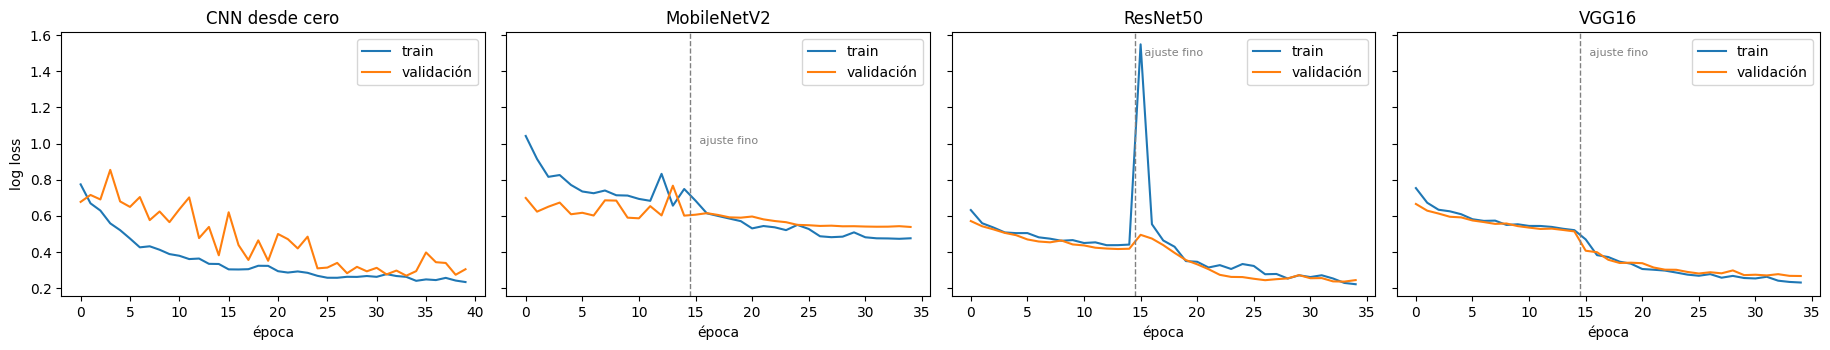

In [8]:
fig, ejes = plt.subplots(1, len(curvas), figsize=(4.6 * len(curvas), 3.6), sharey=True)
for ax, (nombre, (h1, h2)) in zip(ejes, curvas.items()):
    tr = h1["loss"] + (h2["loss"] if h2 else [])
    va = h1["val_loss"] + (h2["val_loss"] if h2 else [])
    ax.plot(tr, label="train"); ax.plot(va, label="validación")
    if h2:
        ax.axvline(len(h1["loss"]) - 0.5, color="grey", ls="--", lw=1)
        ax.text(len(h1["loss"]), ax.get_ylim()[1] * 0.92, " ajuste fino", fontsize=8, color="grey")
    ax.set_title(nombre); ax.set_xlabel("época"); ax.legend()
ejes[0].set_ylabel("log loss")
plt.tight_layout(); plt.show()

## Comparación final

,log_loss,accuracy,auc,recall_iceberg,especificidad,parámetros (M),épocas,tiempo (s)
ResNet50,0.237,0.882,0.966,0.896,0.873,23.59,35.0,270.694
VGG16,0.268,0.873,0.957,0.888,0.862,14.72,35.0,131.962
CNN desde cero,0.270,0.898,0.956,0.948,0.862,0.11,40.0,77.661
MobileNetV2,0.539,0.712,0.795,0.619,0.778,2.26,35.0,187.905


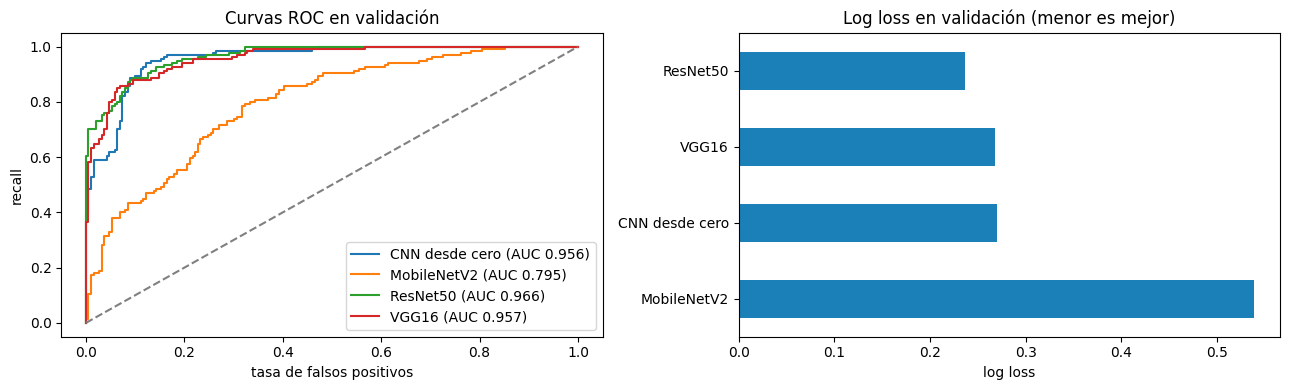

In [9]:
tabla = pd.DataFrame(res).T.drop(columns="probs")
tabla["parametros"] = (tabla["parametros"].astype(float) / 1e6).round(2)
tabla = tabla.rename(columns={"parametros": "parámetros (M)", "segundos": "tiempo (s)", "epocas": "épocas"})
tabla = tabla[["log_loss", "accuracy", "auc", "recall_iceberg", "especificidad", "parámetros (M)", "épocas", "tiempo (s)"]]
tabla = tabla.astype(float).round(3).sort_values("log_loss")
display(tabla)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for nombre, r in res.items():
    fpr, tpr, _ = roc_curve(y_val, r["probs"])
    ejes[0].plot(fpr, tpr, label=f"{nombre} (AUC {r['auc']:.3f})")
ejes[0].plot([0, 1], [0, 1], "--", color="grey"); ejes[0].legend(loc="lower right")
ejes[0].set_xlabel("tasa de falsos positivos"); ejes[0].set_ylabel("recall"); ejes[0].set_title("Curvas ROC en validación")
tabla["log_loss"].plot.barh(ax=ejes[1], color="#1b7fb8"); ejes[1].invert_yaxis()
ejes[1].set_title("Log loss en validación (menor es mejor)"); ejes[1].set_xlabel("log loss")
plt.tight_layout(); plt.show()

In [10]:
mejor = tabla.index[0]
ref = tabla.loc["CNN desde cero"]
print(f"Menor log loss: {mejor} ({tabla.loc[mejor, 'log_loss']:.3f}), con exactitud {tabla.loc[mejor, 'accuracy']:.1%} y AUC {tabla.loc[mejor, 'auc']:.3f}.")
if mejor == "CNN desde cero":
    print("Ningún backbone preentrenado supera a la CNN pequeña en esta partición.")
else:
    print(f"Frente a la CNN desde cero ({ref['log_loss']:.3f}) la mejora de log loss es de {ref['log_loss'] - tabla.loc[mejor, 'log_loss']:.3f}.")
print("Preentrenados, de menor a mayor log loss:",
      ", ".join(f"{n} ({tabla.loc[n, 'log_loss']:.3f})" for n in tabla.index if n != "CNN desde cero"))
print(f"El más ligero fue {tabla['parámetros (M)'].idxmin()} ({tabla['parámetros (M)'].min():.2f} M parámetros) y el más lento "
      f"{tabla['tiempo (s)'].idxmax()} ({tabla['tiempo (s)'].max() / 60:.1f} min).")

Menor log loss: ResNet50 (0.237), con exactitud 88.2% y AUC 0.966.
Frente a la CNN desde cero (0.270) la mejora de log loss es de 0.033.
Preentrenados, de menor a mayor log loss: ResNet50 (0.237), VGG16 (0.268), MobileNetV2 (0.539)
El más ligero fue CNN desde cero (0.11 M parámetros) y el más lento ResNet50 (4.5 min).


**Limitaciones de la comparación**

- Cada modelo se entrenó con **una sola semilla** y una única partición; con ~320 imágenes de validación, diferencias pequeñas de log loss entre modelos no son concluyentes. La variación entre semillas de una CNN pequeña puede ser comparable a esas diferencias.
- La validación se usa también para la parada temprana y para decidir si conservar el ajuste fino, de modo que las métricas son algo optimistas. Un conjunto de prueba independiente daría una estimación más fiel.
- Las imágenes SAR de 75×75 y dos bandas difieren mucho de las fotografías de ImageNet, por lo que el beneficio del preentrenamiento no está garantizado.
- El error más costoso en este problema es no detectar un iceberg; por eso se reportan también el *recall* de iceberg y la especificidad, además del log loss.